# Plot Pareto Frontiers

Hardcoded notebook for plotting the single-agent and ensemble Pareto frontiers in one figure.

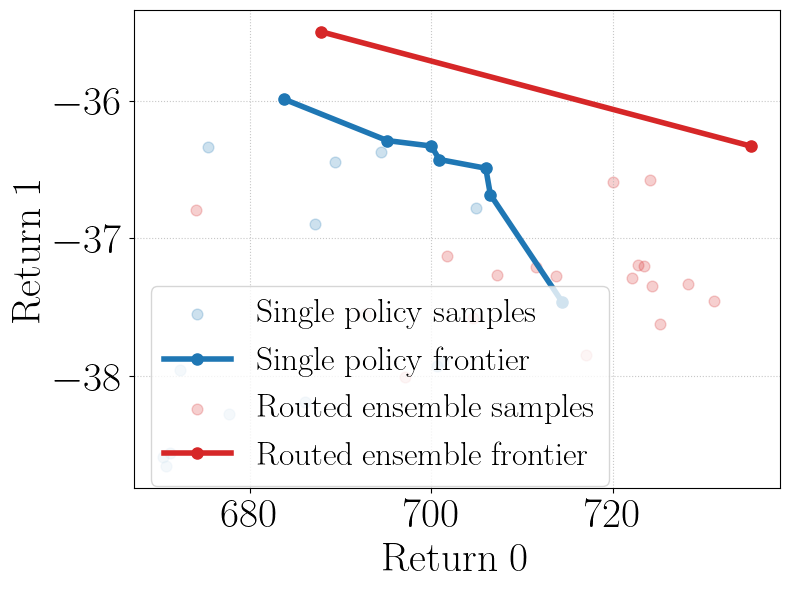

In [17]:
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker

single_csv = Path("./single_returns.csv")
ensemble_csv = Path("./ensemble_returns.csv")


def load_rows(csv_path: Path):
    with csv_path.open(newline="") as handle:
        rows = list(csv.DictReader(handle))
    for row in rows:
        row["return_0"] = float(row["return_0"])
        row["return_1"] = float(row["return_1"])
    return rows


def compute_frontier(rows):
    frontier = []
    for i, row_i in enumerate(rows):
        dominated = False
        for j, row_j in enumerate(rows):
            if i == j:
                continue
            better_or_equal = row_j["return_0"] >= row_i["return_0"] and row_j["return_1"] >= row_i["return_1"]
            strictly_better = row_j["return_0"] > row_i["return_0"] or row_j["return_1"] > row_i["return_1"]
            if better_or_equal and strictly_better:
                dominated = True
                break
        if not dominated:
            frontier.append(row_i)
    frontier.sort(key=lambda row: row["return_0"])
    return frontier


single_rows = load_rows(single_csv)
ensemble_rows = load_rows(ensemble_csv)

single_frontier = compute_frontier(single_rows)
ensemble_frontier = compute_frontier(ensemble_rows)

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    [row["return_0"] for row in single_rows],
    [row["return_1"] for row in single_rows],
    color="#1f77b4",
    alpha=0.22,
    s=60,
    label=r"$\mathrm{Single~policy~samples}$",
)
ax.plot(
    [row["return_0"] for row in single_frontier],
    [row["return_1"] for row in single_frontier],
    color="#1f77b4",
    linewidth=4,
    marker="o",
    markersize=8,
    label=r"$\mathrm{Single~policy~frontier}$",
)

ax.scatter(
    [row["return_0"] for row in ensemble_rows],
    [row["return_1"] for row in ensemble_rows],
    color="#d62728",
    alpha=0.22,
    s=60,
    label=r"$\mathrm{Routed~ensemble~samples}$",
)
ax.plot(
    [row["return_0"] for row in ensemble_frontier],
    [row["return_1"] for row in ensemble_frontier],
    color="#d62728",
    linewidth=4,
    marker="o",
    markersize=8,
    label=r"$\mathrm{Routed~ensemble~frontier}$",
)

# ax.set_title(r"$\mathrm{Pareto~Frontiers}$")
ax.set_xlabel(r"$\mathrm{Return~0}$", fontsize=30)
ax.set_ylabel(r"$\mathrm{Return~1}$", fontsize=30)

ax.tick_params(labelsize=30)
ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.7)
ax.legend(loc="lower left", fontsize=24, bbox_to_anchor=(0.0, -0.03))

fig.tight_layout()
fig.savefig("./pf_halfcheetah.pdf", dpi=1200, bbox_inches="tight")
plt.show()

